In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 2 Curve Fit 

In [89]:
df = pd.read_csv('../../course_assignments/homework9/noisy_curvefit_data.csv')

In [90]:
df.shape

(100, 6)

In [91]:
# This dataset has 100 rows and 6 columns

In [92]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [93]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [94]:
# The column names are: x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5

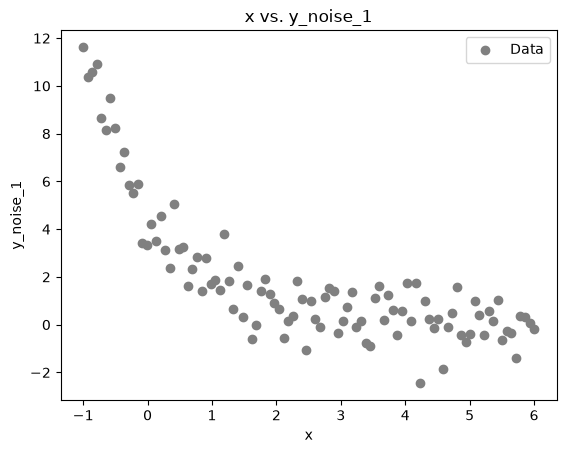

In [95]:
plt.scatter(df["x"], df["y_noise_1"], color = "gray", label = "Data")
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.title("x vs. y_noise_1")
plt.legend()
plt.show()

In [96]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [97]:
p0 = [1, 1]

In [98]:
popt, pcov = curve_fit(model, df["x"], df["y_noise_1"], p0=p0)

In [99]:
A_fit, k_fit = popt

In [100]:
f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)"

'Fit: y = 4.71 * e^(-0.92 * x)'

In [101]:
residuals = df["y_noise_1"] - model(df["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df["x"]) - len(popt)
chi2_reduced = chi2 / dof

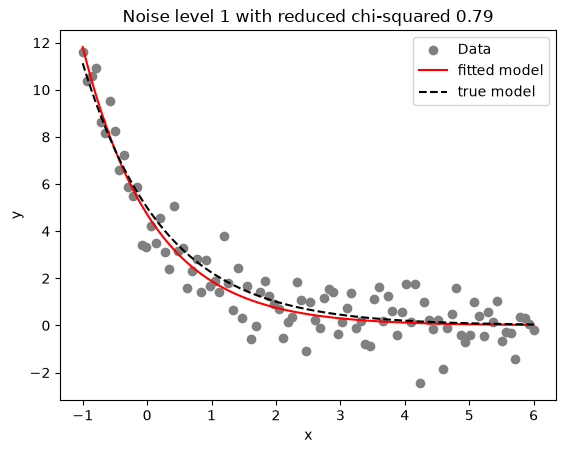

In [102]:
plt.scatter(df["x"], df["y_noise_1"], color = "gray", label = "Data")
plt.plot(df["x"], model(df["x"], A_fit, k_fit), color = "red", label = "fitted model")
plt.plot(df["x"], model(df["x"], 5, 0.8), color = "black", linestyle="--", label = "true model")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise level 1 with reduced chi-squared {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [103]:
def fit_model(x,y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

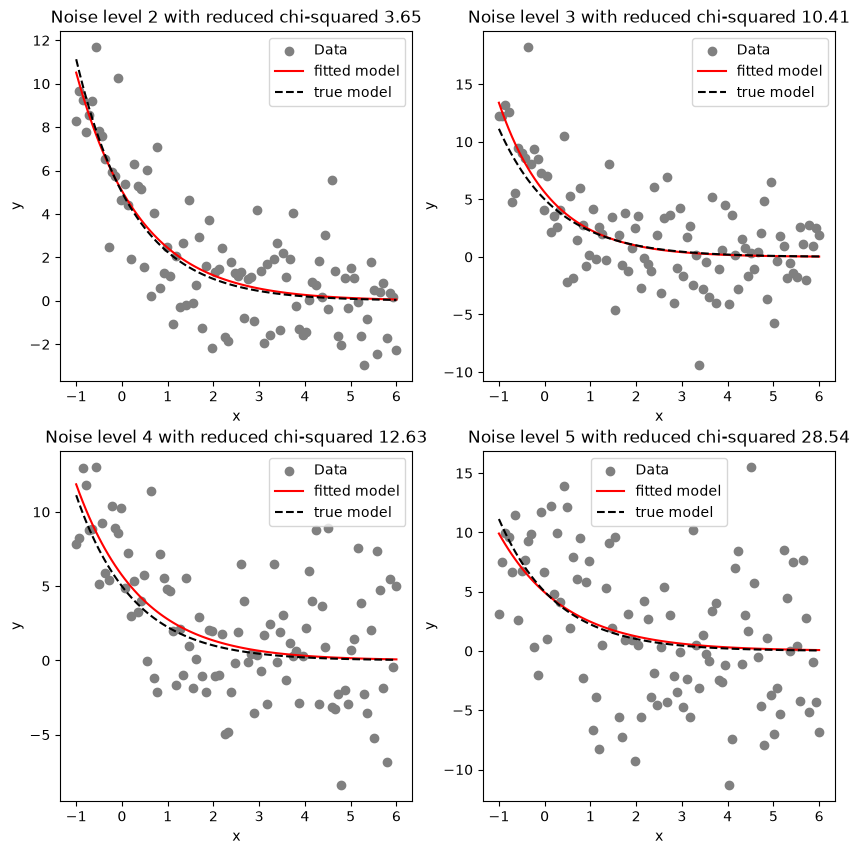

In [104]:
fig, axes = plt.subplots(2,2, figsize = (10,10))
columns = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]
for i, column in enumerate(columns):
    popt, chi2_reduced = fit_model(df["x"], df[column])
    A_fit, k_fit = popt
    axes.flat[i].scatter(df["x"], df[column], color='gray', label='Data')
    axes.flat[i].plot(df["x"], model(df["x"], A_fit, k_fit), color='red', label = "fitted model")
    axes.flat[i].plot(df["x"], model(df["x"], 5, 0.8), color='black', linestyle='--', label = "true model")
    axes.flat[i].set_xlabel("x")
    axes.flat[i].set_ylabel("y")
    axes.flat[i].set_title(f"Noise level {i+2} with reduced chi-squared {chi2_reduced:.2f}")
    axes.flat[i].legend()
plt.show()

In [105]:
# As you increase the noise level, the red line gets less steep and shifts further away from the black line because the data is more spread out and the noisy data makes the fitted model less representative of the true model; the black line stays exactly the same  
# The reduced chi-squared increases meaning the fitted model is becoming a worse fit for the data, this is because the data is less correlated 

In [106]:
columns

['y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']

In [107]:
info = []

for i, col in enumerate(columns):
    popt, chi2_reduced = fit_model(df["x"], df[col])
    A_fit, k_fit = popt
    info.append({"Noise level": i + 2, "A fit": A_fit, "k fit": k_fit, "Reduced chi-squared": chi2_reduced})
info_df = pd.DataFrame(info)

In [108]:
info_df

,Noise level,A fit,k fit,Reduced chi-squared
0,2,5.063889,0.730396,3.649382
1,3,5.609396,0.870372,10.410207
2,4,5.738727,0.725965,12.626832
3,5,4.943458,0.695012,28.538124


In [109]:
info_df.to_csv("noisy_parameters.csv", index=False)